In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

matches = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "matches_cleaned.csv"
)

deliveries = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "deliveries_cleaned.csv"
)

print("Matches Dataset:", matches.shape)
print("Deliveries Dataset:", deliveries.shape)

Matches Dataset: (1095, 20)
Deliveries Dataset: (260920, 17)


In [3]:
print("MATCHES DATASET")
display(matches.head())

print("\nDELIVERIES DATASET")
display(deliveries.head())

MATCHES DATASET


,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan



DELIVERIES DATASET


,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN


In [4]:
print("Matches Info:")
matches.info()

print("\nDeliveries Info:")
deliveries.info()

Matches Info:
<class 'pandas.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1095 non-null   int64  
 1   season           1095 non-null   str    
 2   city             1095 non-null   str    
 3   date             1095 non-null   str    
 4   match_type       1095 non-null   str    
 5   player_of_match  1090 non-null   str    
 6   venue            1095 non-null   str    
 7   team1            1095 non-null   str    
 8   team2            1095 non-null   str    
 9   toss_winner      1095 non-null   str    
 10  toss_decision    1095 non-null   str    
 11  winner           1090 non-null   str    
 12  result           1095 non-null   str    
 13  result_margin    1076 non-null   float64
 14  target_runs      1092 non-null   float64
 15  target_overs     1092 non-null   float64
 16  super_over       1095 non-null   str    
 17  method     

In [5]:
all_teams = pd.concat([matches['team1'], matches['team2']])

matches_played = all_teams.value_counts()

matches_played = matches_played.reset_index()

matches_played.columns = ['team', 'matches_played']

display(matches_played)

,team,matches_played
0,Mumbai Indians,261
1,Kolkata Knight Riders,251
2,Royal Challengers Bangalore,240
3,Chennai Super Kings,238
4,Rajasthan Royals,221
5,Kings XI Punjab,190
6,Sunrisers Hyderabad,182
7,Delhi Daredevils,161
8,Delhi Capitals,91
9,Deccan Chargers,75


In [6]:
matches_won = matches['winner'].value_counts()

matches_won = matches_won.reset_index()

matches_won.columns = ['team', 'matches_won']

display(matches_won)

,team,matches_won
0,Mumbai Indians,144
1,Chennai Super Kings,138
2,Kolkata Knight Riders,131
3,Royal Challengers Bangalore,116
4,Rajasthan Royals,112
5,Kings XI Punjab,88
6,Sunrisers Hyderabad,88
7,Delhi Daredevils,67
8,Delhi Capitals,48
9,Deccan Chargers,29


In [7]:
team_performance = pd.merge(
    matches_played,
    matches_won,
    on='team',
    how='left'
)


team_performance['matches_won'] = (
    team_performance['matches_won'].fillna(0)
)

team_performance['win_percentage'] = (
    team_performance['matches_won'] /
    team_performance['matches_played']
) * 100

team_performance['win_percentage'] = (
    team_performance['win_percentage'].round(2)
)

team_performance = team_performance.sort_values(
    by='matches_won',
    ascending=False
)

display(team_performance)

,team,matches_played,matches_won,win_percentage
0,Mumbai Indians,261,144,55.17
3,Chennai Super Kings,238,138,57.98
1,Kolkata Knight Riders,251,131,52.19
2,Royal Challengers Bangalore,240,116,48.33
4,Rajasthan Royals,221,112,50.68
5,Kings XI Punjab,190,88,46.32
6,Sunrisers Hyderabad,182,88,48.35
7,Delhi Daredevils,161,67,41.61
8,Delhi Capitals,91,48,52.75
9,Deccan Chargers,75,29,38.67


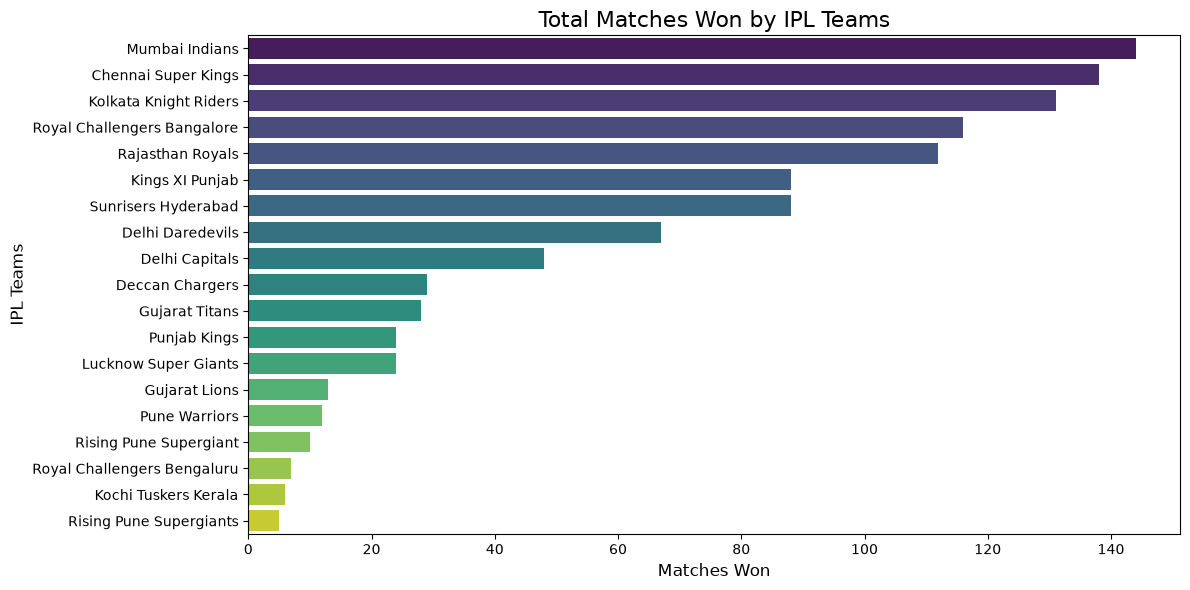

In [8]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=team_performance,
    x='matches_won',
    y='team',
    hue='team',
    palette='viridis',
    legend=False
)

plt.title('Total Matches Won by IPL Teams', fontsize=16)
plt.xlabel('Matches Won', fontsize=12)
plt.ylabel('IPL Teams', fontsize=12)

plt.tight_layout()
plt.show()

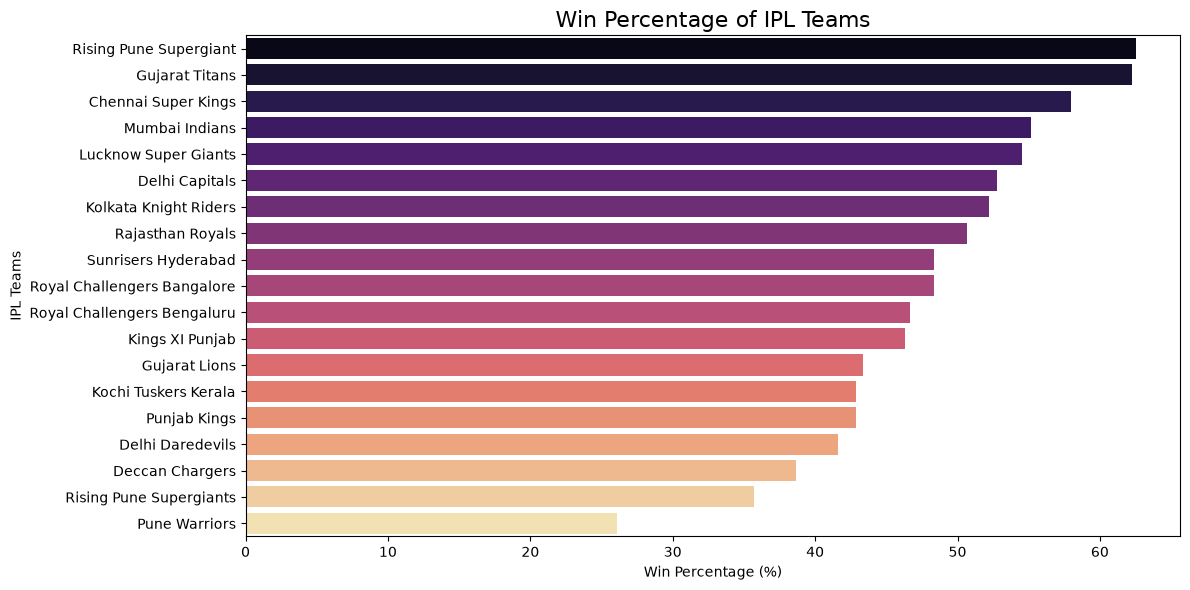

In [9]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=team_performance.sort_values(
        by='win_percentage',
        ascending=False
    ),
    x='win_percentage',
    y='team',
    hue='team',
    palette='magma',
    legend=False
)

plt.title('Win Percentage of IPL Teams', fontsize=16)
plt.xlabel('Win Percentage (%)')
plt.ylabel('IPL Teams')

plt.tight_layout()
plt.show()

In [10]:
matches['toss_match_winner'] = (
    matches['toss_winner'] == matches['winner']
)

toss_results = matches['toss_match_winner'].value_counts()

print(toss_results)

toss_match_winner
True     554
False    541
Name: count, dtype: int64


In [11]:
valid_matches = matches['winner'].notna().sum()

toss_wins = (
    matches['toss_match_winner'].sum()
)

toss_win_percentage = (
    toss_wins / valid_matches
) * 100

print(f"Toss Winning Success Rate: {toss_win_percentage:.2f}%")

Toss Winning Success Rate: 50.83%


In [12]:
decision_analysis = matches.groupby('toss_decision').agg(
    total_matches=('toss_decision', 'count'),
    matches_won=('toss_match_winner', 'sum')
)

display(decision_analysis)

,total_matches,matches_won
toss_decision,,
bat,391,177
field,704,377


In [13]:
valid_decisions = matches.groupby('toss_decision').agg(
    valid_matches=('winner', 'count')
)

decision_analysis = decision_analysis.join(valid_decisions)

decision_analysis['win_percentage'] = (
    decision_analysis['matches_won'] /
    decision_analysis['valid_matches']
) * 100

decision_analysis['win_percentage'] = (
    decision_analysis['win_percentage'].round(2)
)

display(decision_analysis)

,total_matches,matches_won,valid_matches,win_percentage
toss_decision,,,,
bat,391,177,390,45.38
field,704,377,700,53.86


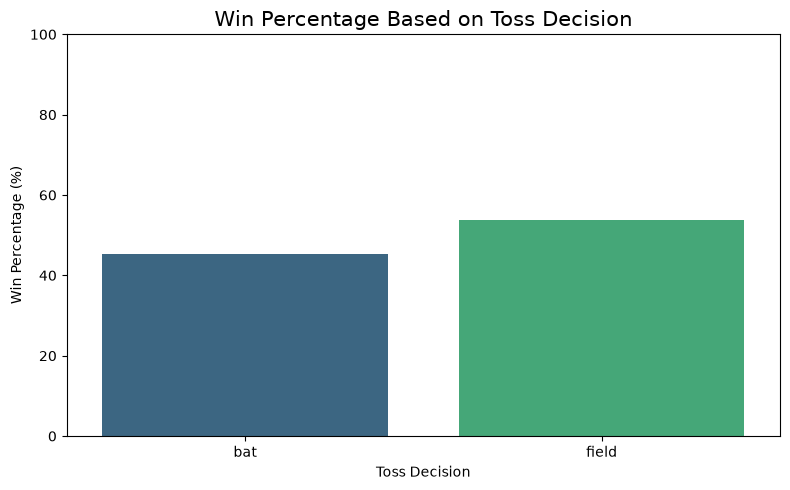

In [14]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=decision_analysis.reset_index(),
    x='toss_decision',
    y='win_percentage',
    hue='toss_decision',
    palette='viridis',
    legend=False
)

plt.title('Win Percentage Based on Toss Decision', fontsize=15)
plt.xlabel('Toss Decision')
plt.ylabel('Win Percentage (%)')

plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [23]:
top_run_scorers = deliveries.groupby('batter')['batsman_runs'].sum()

top_run_scorers = top_run_scorers.sort_values(
    ascending=False
)

top_10_batsmen = top_run_scorers.head(10)

display(top_10_batsmen)

batter
V Kohli           8014
S Dhawan          6769
RG Sharma         6630
DA Warner         6567
SK Raina          5536
MS Dhoni          5243
AB de Villiers    5181
CH Gayle          4997
RV Uthappa        4954
KD Karthik        4843
Name: batsman_runs, dtype: int64

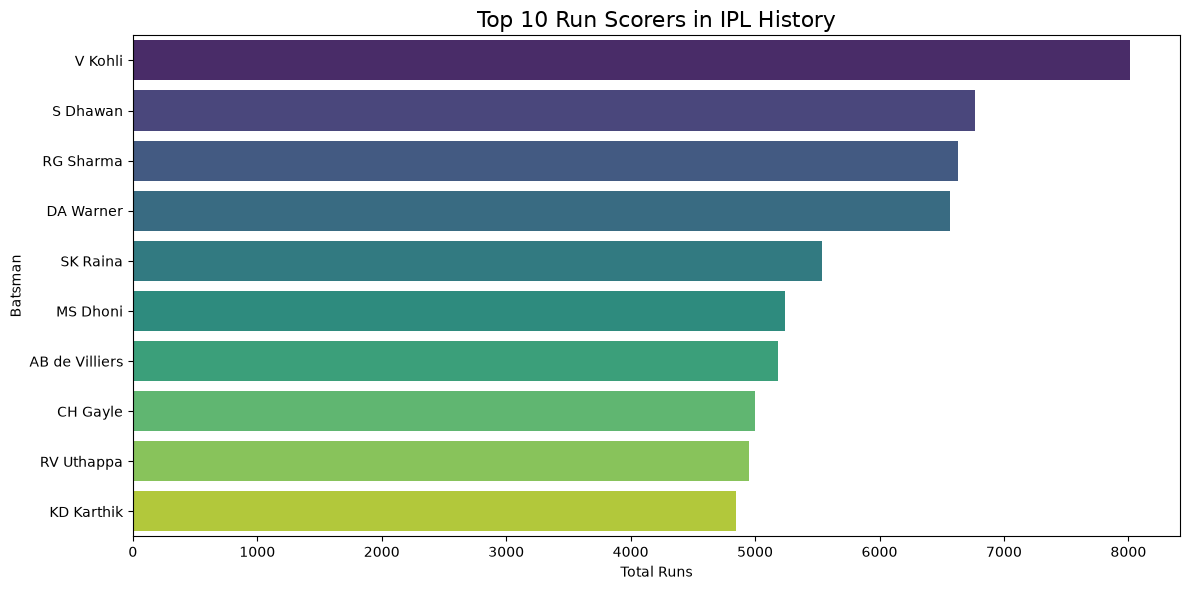

In [16]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_batsmen.values,
    y=top_10_batsmen.index,
    hue=top_10_batsmen.index,
    palette='viridis',
    legend=False
)

plt.title('Top 10 Run Scorers in IPL History', fontsize=16)
plt.xlabel('Total Runs')
plt.ylabel('Batsman')

plt.tight_layout()
plt.show()

In [21]:
fours = deliveries[deliveries['batsman_runs'] == 4]

most_fours = fours.groupby('batter').size()

most_fours = most_fours.sort_values(ascending=False)

top_10_fours = most_fours.head(10)

display(top_10_fours)

batter
S Dhawan        768
V Kohli         708
DA Warner       663
RG Sharma       599
SK Raina        506
G Gambhir       492
RV Uthappa      481
AM Rahane       479
KD Karthik      466
F du Plessis    422
dtype: int64

In [18]:
sixes = deliveries[deliveries['batsman_runs'] == 6]

most_sixes = sixes.groupby('batter').size()

most_sixes = most_sixes.sort_values(ascending=False)

top_10_sixes = most_sixes.head(10)

display(top_10_sixes)

batter
CH Gayle          359
RG Sharma         281
V Kohli           273
AB de Villiers    253
MS Dhoni          252
DA Warner         236
KA Pollard        224
AD Russell        209
SV Samson         206
SK Raina          204
dtype: int64

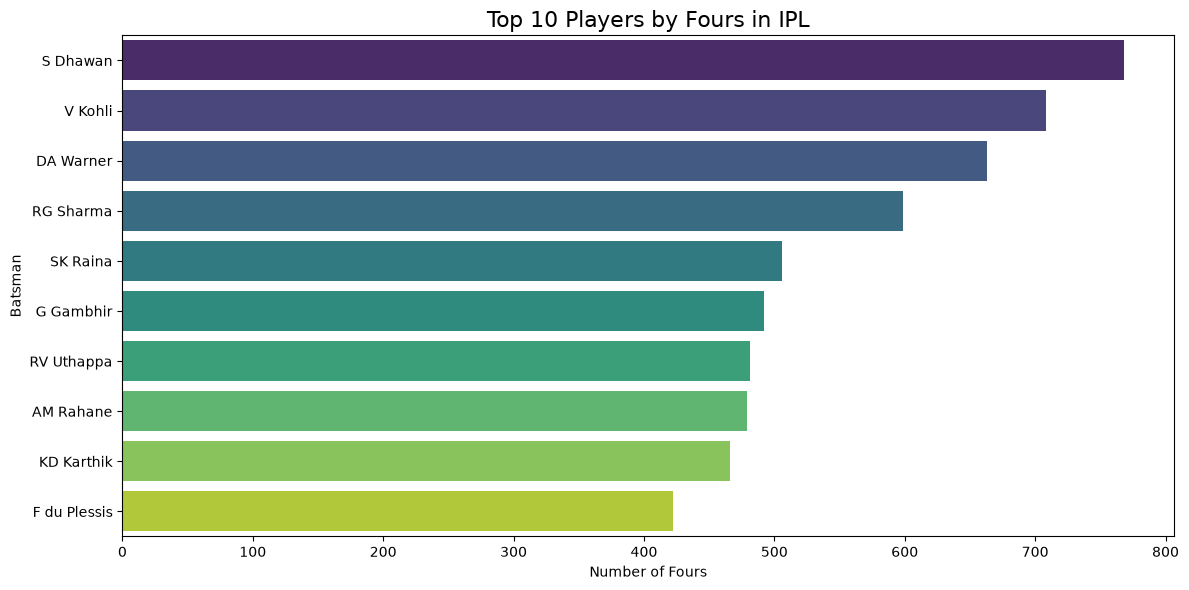

In [24]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_fours.values,
    y=top_10_fours.index,
    hue=top_10_fours.index,
    palette='viridis',
    legend=False
)

plt.title('Top 10 Players by Fours in IPL', fontsize=16)
plt.xlabel('Number of Fours')
plt.ylabel('Batsman')

plt.tight_layout()
plt.show()

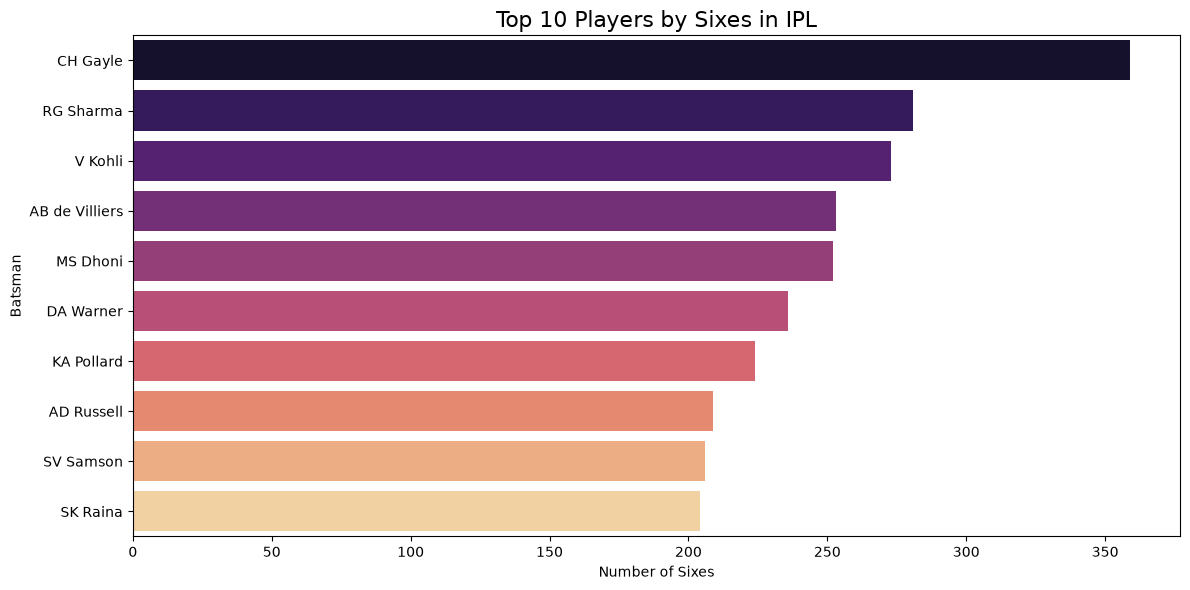

In [25]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_sixes.values,
    y=top_10_sixes.index,
    hue=top_10_sixes.index,
    palette='magma',
    legend=False
)

plt.title('Top 10 Players by Sixes in IPL', fontsize=16)
plt.xlabel('Number of Sixes')
plt.ylabel('Batsman')

plt.tight_layout()
plt.show()

In [26]:
individual_scores = deliveries.groupby(
    ['match_id', 'batter']
)['batsman_runs'].sum().reset_index()

individual_scores = individual_scores.sort_values(
    by='batsman_runs',
    ascending=False
)

top_10_individual_scores = individual_scores.head(10)

display(top_10_individual_scores)

,match_id,batter,batsman_runs
5302,598027,CH Gayle,175
2,335982,BB McCullum,158
14108,1304112,Q de Kock,140
7528,829795,AB de Villiers,133
11583,1216510,KL Rahul,132
15383,1370352,Shubman Gill,129
8359,980987,AB de Villiers,129
4687,548372,CH Gayle,128
10149,1136602,RR Pant,128
2237,419137,M Vijay,127


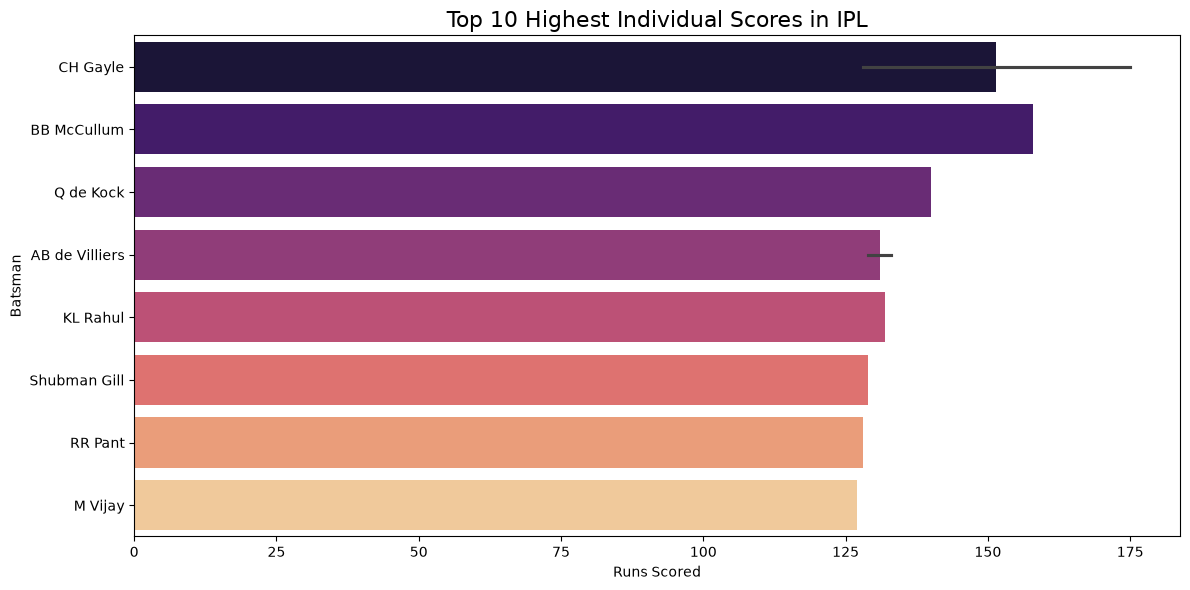

In [27]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_individual_scores,
    x='batsman_runs',
    y='batter',
    hue='batter',
    palette='magma',
    legend=False
)

plt.title('Top 10 Highest Individual Scores in IPL', fontsize=16)
plt.xlabel('Runs Scored')
plt.ylabel('Batsman')

plt.tight_layout()
plt.show()

In [31]:
bowler_dismissals = [
    'bowled',
    'caught',
    'caught and bowled',
    'lbw',
    'stumped',
    'hit wicket'
]

wickets = deliveries[
    deliveries['dismissal_kind'].isin(bowler_dismissals)
]

bowler_wickets = wickets.groupby('bowler').size()

bowler_wickets = bowler_wickets.sort_values(
    ascending=False
)

top_10_bowlers = bowler_wickets.head(10)

display(top_10_bowlers)

bowler
YS Chahal     205
PP Chawla     192
DJ Bravo      183
B Kumar       181
R Ashwin      180
SP Narine     180
A Mishra      174
SL Malinga    170
JJ Bumrah     168
RA Jadeja     160
dtype: int64

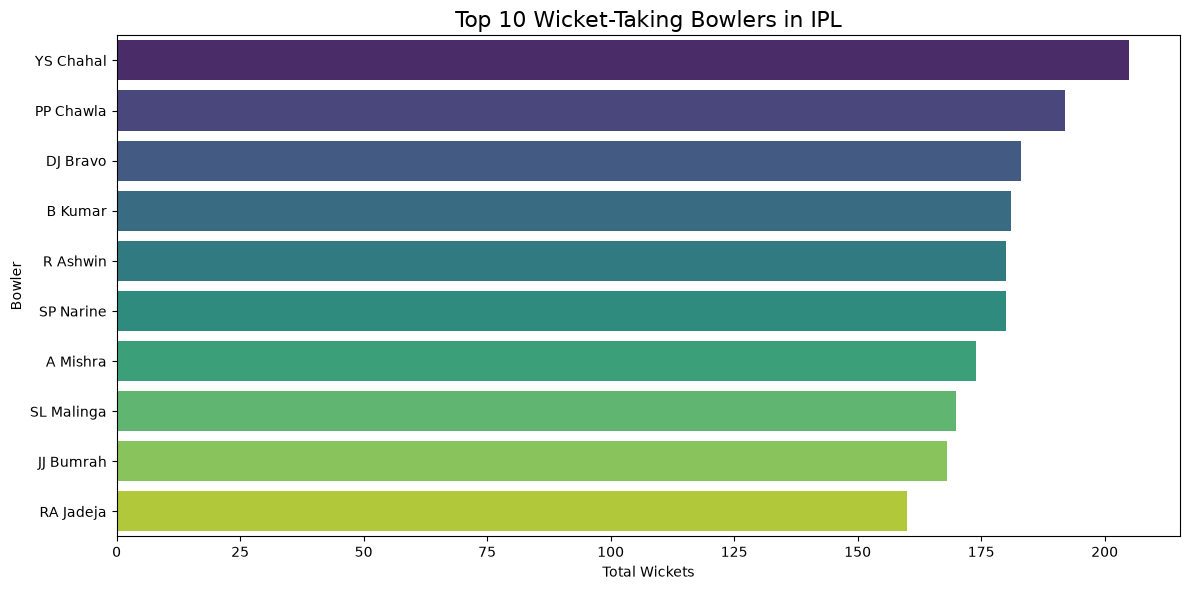

In [32]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_bowlers.values,
    y=top_10_bowlers.index,
    hue=top_10_bowlers.index,
    palette='viridis',
    legend=False
)

plt.title('Top 10 Wicket-Taking Bowlers in IPL', fontsize=16)
plt.xlabel('Total Wickets')
plt.ylabel('Bowler')

plt.tight_layout()
plt.show()

In [33]:
venue_matches = matches['venue'].value_counts()

top_10_venues = venue_matches.head(10)

display(top_10_venues)

venue
Eden Gardens                                  77
Wankhede Stadium                              73
M Chinnaswamy Stadium                         65
Feroz Shah Kotla                              60
Rajiv Gandhi International Stadium, Uppal     49
MA Chidambaram Stadium, Chepauk               48
Sawai Mansingh Stadium                        47
Dubai International Cricket Stadium           46
Wankhede Stadium, Mumbai                      45
Punjab Cricket Association Stadium, Mohali    35
Name: count, dtype: int64

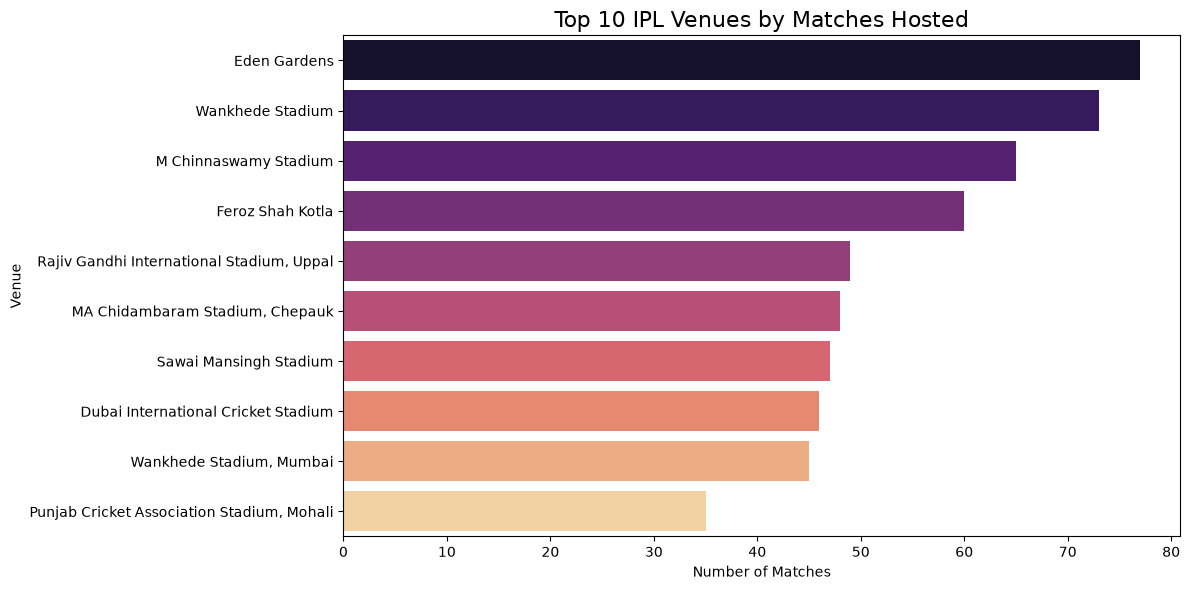

In [34]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_venues.values,
    y=top_10_venues.index,
    hue=top_10_venues.index,
    palette='magma',
    legend=False
)

plt.title('Top 10 IPL Venues by Matches Hosted', fontsize=16)
plt.xlabel('Number of Matches')
plt.ylabel('Venue')

plt.tight_layout()
plt.show()

In [35]:
match_runs = deliveries.groupby('match_id')['total_runs'].sum()

match_runs = match_runs.reset_index(name='total_runs')

display(match_runs.head())

,match_id,total_runs
0,335982,304
1,335983,447
2,335984,261
3,335985,331
4,335986,222


In [36]:
match_seasons = matches[['id', 'season']]

season_runs = match_runs.merge(
    match_seasons,
    left_on='match_id',
    right_on='id'
)

season_runs = season_runs[['season', 'match_id', 'total_runs']]

display(season_runs.head())

,season,match_id,total_runs
0,2007/08,335982,304
1,2007/08,335983,447
2,2007/08,335984,261
3,2007/08,335985,331
4,2007/08,335986,222


In [37]:
season_avg_runs = (
    season_runs.groupby('season', sort=False)['total_runs']
    .mean()
    .reset_index(name='average_runs')
)

season_avg_runs['average_runs'] = season_avg_runs['average_runs'].round(2)

display(season_avg_runs)

,season,average_runs
0,2007/08,309.26
1,2009,286.89
2,2009/10,314.72
3,2011,289.78
4,2012,303.42
5,2013,297.39
6,2014,315.52
7,2015,311.07
8,2016,314.37
9,2017,318.41


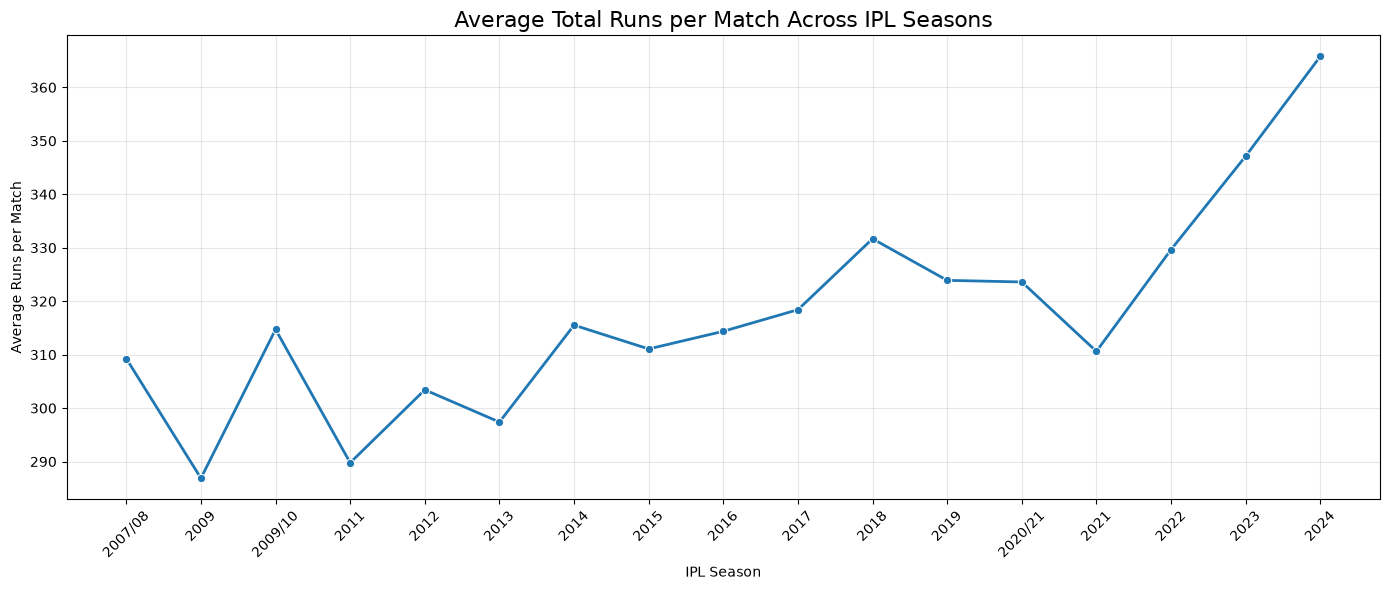

In [38]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=season_avg_runs,
    x='season',
    y='average_runs',
    marker='o',
    linewidth=2
)

plt.title('Average Total Runs per Match Across IPL Seasons', fontsize=16)
plt.xlabel('IPL Season')
plt.ylabel('Average Runs per Match')

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [39]:
individual_scores = (
    deliveries.groupby(
        ['match_id', 'inning', 'batter']
    )['batsman_runs']
    .sum()
    .reset_index()
)

individual_scores = individual_scores.sort_values(
    by='batsman_runs',
    ascending=False
)

top_10_individual_scores = individual_scores.head(10)

display(top_10_individual_scores)

,match_id,inning,batter,batsman_runs
5315,598027,1,CH Gayle,175
0,335982,1,BB McCullum,158
14171,1304112,1,Q de Kock,140
7556,829795,1,AB de Villiers,133
11623,1216510,1,KL Rahul,132
8387,980987,1,AB de Villiers,129
15441,1370352,1,Shubman Gill,129
4694,548372,1,CH Gayle,128
10179,1136602,1,RR Pant,128
2242,419137,1,M Vijay,127


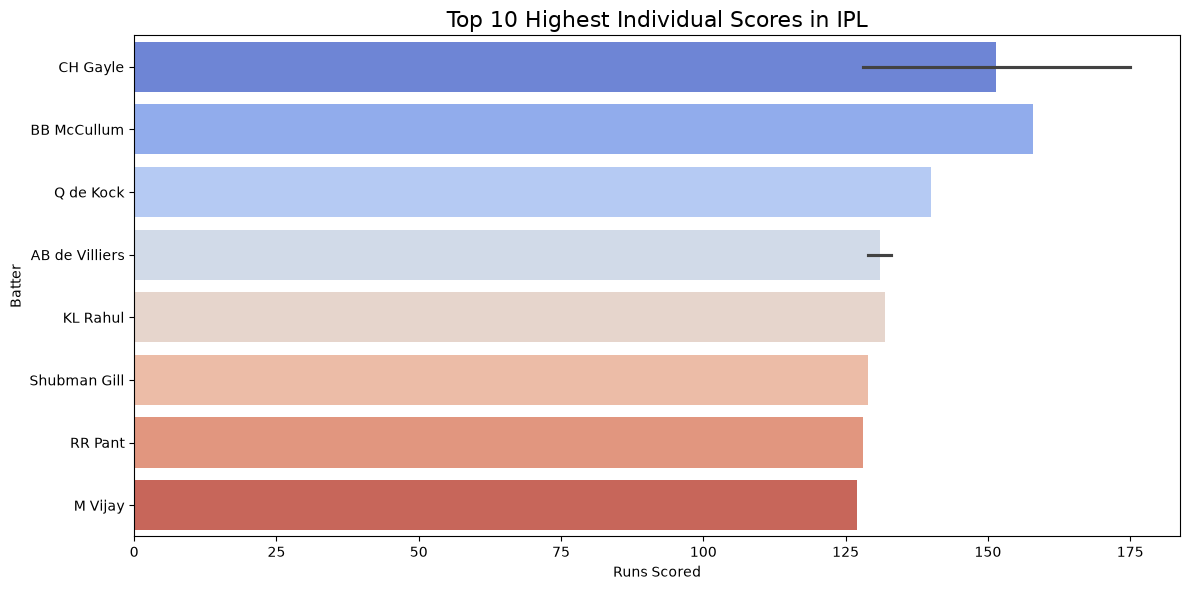

In [40]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_individual_scores,
    x='batsman_runs',
    y='batter',
    hue='batter',
    palette='coolwarm',
    legend=False
)

plt.title('Top 10 Highest Individual Scores in IPL', fontsize=16)
plt.xlabel('Runs Scored')
plt.ylabel('Batter')

plt.tight_layout()
plt.show()

# IPLytics — Exploratory Data Analysis (EDA) Report

## 1. Overview

Day 3 focused on performing Exploratory Data Analysis (EDA) on the cleaned IPL datasets.

The objective was to discover meaningful patterns, compare team and player performances, analyze toss impact, investigate venue statistics, and understand scoring trends across IPL seasons.

### Datasets Used

| Dataset | Rows | Columns |
|---|---:|---:|
| Matches | 1,095 | 20 |
| Deliveries | 260,920 | 17 |

**Input files:**
- `data/processed/matches_cleaned.csv`
- `data/processed/deliveries_cleaned.csv`

**Notebook:** `notebooks/03_eda.ipynb`

---

## 2. Team Performance Analysis

Analyzed the number of matches played, matches won, and win percentages for IPL teams.

### Key Findings

- Mumbai Indians played the most matches: **261**.
- Chennai Super Kings recorded a win percentage of **57.98%** across 238 matches.
- Gujarat Titans recorded a win percentage of **62.22%** across 45 matches.
- Rising Pune Supergiant recorded a win percentage of **62.50%** across 16 matches.

### Top Teams by Matches Played

| Team | Matches Played |
|---|---:|
| Mumbai Indians | 261 |
| Kolkata Knight Riders | 251 |
| Royal Challengers Bangalore | 240 |
| Chennai Super Kings | 238 |
| Rajasthan Royals | 221 |

### Visualizations Created

1. Top teams by matches played.
2. Top teams by matches won.
3. Team win percentage comparison.

**Observation:** Historical franchise names are represented separately in the dataset. For example, Kings XI Punjab and Punjab Kings are not combined. This should be considered when comparing franchise performance.

---

## 3. Toss Impact Analysis

Investigated whether winning the toss is associated with winning the match.

### Key Findings

- Total matches with a recorded winner: **1,090**.
- Matches where the toss winner also won the match: **554**.
- Toss-winning teams also won approximately **50.83%** of valid matches.

### Toss Decision Analysis

| Toss Decision | Total Matches | Valid Matches | Matches Won | Win Percentage |
|---|---:|---:|---:|---:|
| Bat | 391 | 390 | 177 | 45.38% |
| Field | 704 | 700 | 377 | 53.86% |

### Visualization Created

- Comparison of match win percentages for teams choosing to bat and field after winning the toss.

**Observation:** Teams choosing to field had a higher match win percentage (53.86%) than teams choosing to bat (45.38%) in this dataset.

This indicates an association, not proof that choosing to field causes a team to win.

---

## 4. Batting Performance Analysis

Analyzed individual batting performances using the deliveries dataset.

### 4.1 Top 10 Run Scorers

| Rank | Batter | Runs |
|---:|---|---:|
| 1 | V Kohli | 8,014 |
| 2 | S Dhawan | 6,769 |
| 3 | RG Sharma | 6,630 |
| 4 | DA Warner | 6,567 |
| 5 | SK Raina | 5,536 |
| 6 | MS Dhoni | 5,243 |
| 7 | AB de Villiers | 5,181 |
| 8 | CH Gayle | 4,997 |
| 9 | RV Uthappa | 4,954 |
| 10 | KD Karthik | 4,843 |

**Finding:** Virat Kohli leads the run-scoring leaderboard with 8,014 runs.

### 4.2 Top 10 Players by Fours

| Rank | Batter | Fours |
|---:|---|---:|
| 1 | S Dhawan | 768 |
| 2 | V Kohli | 708 |
| 3 | DA Warner | 663 |
| 4 | RG Sharma | 599 |
| 5 | SK Raina | 506 |
| 6 | G Gambhir | 492 |
| 7 | RV Uthappa | 481 |
| 8 | AM Rahane | 479 |
| 9 | KD Karthik | 466 |
| 10 | F du Plessis | 422 |

**Finding:** Shikhar Dhawan leads the fours leaderboard with 768 fours.

### 4.3 Top 10 Players by Sixes

| Rank | Batter | Sixes |
|---:|---|---:|
| 1 | CH Gayle | 359 |
| 2 | RG Sharma | 281 |
| 3 | V Kohli | 273 |
| 4 | AB de Villiers | 253 |
| 5 | MS Dhoni | 252 |
| 6 | DA Warner | 236 |
| 7 | KA Pollard | 224 |
| 8 | AD Russell | 209 |
| 9 | SV Samson | 206 |
| 10 | SK Raina | 204 |

**Finding:** Chris Gayle leads the sixes leaderboard with 359 sixes.

### 4.4 Highest Individual Innings Scores

Grouped deliveries by match ID, innings, and batter to calculate individual innings scores.

| Rank | Batter | Runs |
|---:|---|---:|
| 1 | CH Gayle | 175 |
| 2 | BB McCullum | 158 |
| 3 | Q de Kock | 140 |
| 4 | AB de Villiers | 133 |
| 5 | KL Rahul | 132 |
| 6 | AB de Villiers | 129 |
| 7 | Shubman Gill | 129 |
| 8 | CH Gayle | 128 |
| 9 | RR Pant | 128 |
| 10 | M Vijay | 127 |

**Finding:** Chris Gayle's 175 remains the highest individual innings score in the dataset.

### Visualizations Created

1. Top 10 run scorers.
2. Top 10 players by fours.
3. Top 10 players by sixes.
4. Top 10 highest individual innings scores.

---

## 5. Bowling Performance Analysis

Analyzed bowler-credited dismissals to identify the leading wicket-takers.

The following dismissal types were considered:

- Bowled
- Caught
- Caught and bowled
- LBW
- Stumped
- Hit wicket

Run-outs and other dismissals not credited to the bowler were excluded.

### Top 10 Wicket-Taking Bowlers

| Rank | Bowler | Wickets |
|---:|---|---:|
| 1 | YS Chahal | 205 |
| 2 | PP Chawla | 192 |
| 3 | DJ Bravo | 183 |
| 4 | B Kumar | 181 |
| 5 | R Ashwin | 180 |
| 6 | SP Narine | 180 |
| 7 | A Mishra | 174 |
| 8 | SL Malinga | 170 |
| 9 | JJ Bumrah | 168 |
| 10 | RA Jadeja | 160 |

**Finding:** Yuzvendra Chahal leads the wicket-taking leaderboard with 205 bowler-credited wickets.

### Visualization Created

- Top 10 wicket-taking bowlers.

---

## 6. Venue Analysis

Analyzed the number of IPL matches hosted at different venues.

### Top 10 IPL Venues

| Rank | Venue | Matches |
|---:|---|---:|
| 1 | Eden Gardens | 77 |
| 2 | Wankhede Stadium | 73 |
| 3 | M Chinnaswamy Stadium | 65 |
| 4 | Feroz Shah Kotla | 60 |
| 5 | Rajiv Gandhi International Stadium, Uppal | 49 |
| 6 | MA Chidambaram Stadium, Chepauk | 48 |
| 7 | Sawai Mansingh Stadium | 47 |
| 8 | Dubai International Cricket Stadium | 46 |
| 9 | Wankhede Stadium, Mumbai | 45 |
| 10 | Punjab Cricket Association Stadium, Mohali | 35 |

**Finding:** Eden Gardens hosted the highest number of matches in the dataset, with 77 matches.

**Observation:** Wankhede Stadium appears under two different names. This indicates venue-name inconsistencies that may require standardization in a future improvement.

### Visualization Created

- Top 10 IPL venues by matches hosted.

---

## 7. Season-Wise Scoring Trends

Analyzed the average combined runs scored by both teams in a match across IPL seasons.

### Methodology

1. Grouped deliveries by match ID.
2. Calculated total runs scored in each match.
3. Merged match totals with the season information.
4. Grouped the results by season.
5. Calculated average total runs per match.

### Average Total Runs Per Match

| Season | Average Runs |
|---|---:|
| 2007/08 | 309.26 |
| 2009 | 286.89 |
| 2009/10 | 314.72 |
| 2011 | 289.78 |
| 2012 | 303.42 |
| 2013 | 297.39 |
| 2014 | 315.52 |
| 2015 | 311.07 |
| 2016 | 314.37 |
| 2017 | 318.41 |
| 2018 | 331.68 |
| 2019 | 323.90 |
| 2020/21 | 323.60 |
| 2021 | 310.62 |
| 2022 | 329.66 |
| 2023 | 347.14 |
| 2024 | 365.79 |

### Key Findings

- Highest average combined runs: **2024 — 365.79**.
- Lowest average combined runs: **2009 — 286.89**.
- The later seasons in this dataset show generally higher average combined scores.

### Visualization Created

- Line chart showing average total runs per match across IPL seasons.

---

## 8. Overall Key Insights

The following insights were identified during Day 3:

1. Mumbai Indians played the most matches among the listed franchise names.
2. Chennai Super Kings recorded a 57.98% win percentage under its original franchise name.
3. Toss winners won approximately 50.83% of matches with a recorded winner.
4. Teams choosing to field had a higher win percentage than teams choosing to bat in the toss-decision analysis.
5. Virat Kohli leads the run-scoring leaderboard.
6. Shikhar Dhawan leads the fours leaderboard.
7. Chris Gayle leads the sixes leaderboard and holds the highest individual innings score in this dataset.
8. Yuzvendra Chahal leads the bowler-credited wicket-taking leaderboard.
9. Eden Gardens hosted the most matches.
10. The average combined match score was highest in the 2024 season.

---

## 9. Important Data Considerations

Some limitations and inconsistencies were identified during analysis:

- Historical franchise names have not yet been standardized.
- Some venues appear under multiple names.
- Toss analysis measures association, not causation.
- Five matches without a recorded winner were excluded from the toss win-percentage denominator.
- Bowling wicket counts exclude dismissals that are not credited to bowlers.
- Season-wise averages represent combined runs scored by both teams, not an individual team's average score.

These considerations should be addressed or documented when presenting the final project.

---

## 10. Conclusion

Using Pandas, NumPy, Matplotlib, and Seaborn, the project explored team performance, toss impact, batting statistics, bowling statistics, venue statistics, and season-wise scoring trends.

Multiple visualizations were created to communicate the findings clearly.

The analysis provides a foundation for more advanced cricket statistics and insights in the next stage of the project.

